# Phase 4 — Drift Detector Comparison

Implements Chapter 3, Section 3.5 and Chapter 4, Section 4.6 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Compares ADWIN, DDM, and Page-Hinkley, all applied to the same signal: the per-row
prediction-error stream of the best static model from Phase 2. This comparison is
explicitly conditioned on that model choice (Chapter 3, Table 3.4, Stage 3) -- DDM in
particular is inherently error-rate-based and cannot be evaluated without a fitted model.

Two complementary evaluation strategies are used, directly addressing the concern that
judging detectors only by downstream predictive accuracy would collapse detector
evaluation into model evaluation (Chapter 3, Section 3.5.1):

1. **Synthetic drift injection**: known, labelled drift points are introduced into a copy
   of the test stream, giving ground-truth timestamps against which detection delay and
   false-positive rate are measured.
2. **Observed behaviour on the real stream**: drift count and runtime on the unmodified
   test stream, characterising practical behaviour on genuine data.

**Output:**
- `results/tables/phase4_synthetic_evaluation.csv` — detection delay / false positives per detector
- `results/tables/phase4_real_stream_evaluation.csv` — drift count / runtime per detector
- `results/figures/phase4_synthetic_drift_detection.png` — error stream with true drift points and alarms
- `results/tables/phase4_artifacts.json` — the chosen detector, consumed by Phases 5–9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load Phase 2 and Phase 3 artefacts, and the test stream

The best model (Phase 2) provides the error signal every detector monitors. The window length (Phase 3) is not used as the detector's own update granularity (Section 3.5's docstring in `drift_detectors.py` explains why) -- it is loaded here only so it is available downstream once a detector fires (Phase 5 onward).

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p3 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase3_artifacts.json'))

best_model_name = artifacts_p2['best_model']
feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']
window_size = artifacts_p3['chosen_window_size']

best_model = mdl.load_model(os.path.join(PROJECT_ROOT, f'results/models/{best_model_name}.joblib'))
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))

print('Model:', mdl.MODEL_DISPLAY_NAMES[best_model_name])
print('Window length (for later phases):', window_size)
print('Test stream:', len(test_df), 'rows')

Model: Random Forest
Window length (for later phases): 4000
Test stream: 10000 rows


## 2. Synthetic drift injection

The test stream is split into four segments by three injection points, and the target variable is scaled within each segment to simulate sustained regime shifts (Chapter 3, Section 3.5.1; see `drift_detectors.inject_synthetic_drift` for the full rationale). Since the model is fixed (not retrained here), a scaled target reliably and predictably increases the model's error from each injection point onward.

In [5]:
n = len(test_df)
INJECTION_POINTS = [n // 4, n // 2, 3 * n // 4]        # three evenly spaced true drift points
SCALE_FACTORS = [1.0, 1.35, 0.75, 1.5]                  # baseline, then one factor per segment

injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=INJECTION_POINTS, scale_factors=SCALE_FACTORS,
)

print('True drift points (row indices):', injection.true_drift_indices)
print('Segment boundaries:', injection.segment_bounds)
print('Scale factors applied per segment:', SCALE_FACTORS)

True drift points (row indices): [2500, 5000, 7500]
Segment boundaries: [(0, 2500), (2500, 5000), (5000, 7500), (7500, 10000)]
Scale factors applied per segment: [1.0, 1.35, 0.75, 1.5]


In [6]:
X_synth = injection.df[feature_cols]
y_synth = injection.df[target_col]
synthetic_error_stream = dd.compute_error_stream(best_model, X_synth, y_synth)

print('Synthetic error stream: mean', round(synthetic_error_stream.mean(), 3),
      '| max', round(synthetic_error_stream.max(), 3))

Synthetic error stream: mean 2.317 | max 11.618


## 3. Run all three detectors on the synthetic stream

ADWIN and Page-Hinkley consume the continuous error value directly. DDM requires a binary error indicator (Section 2.6.2 / 3.5), so the continuous error is thresholded using the mean + 1 standard deviation of the baseline (first, unscaled) segment -- a threshold derived only from pre-drift data, not from the injected segments themselves.

In [7]:
baseline_errors = synthetic_error_stream[:injection.segment_bounds[0][1]]
ddm_threshold = baseline_errors.mean() + baseline_errors.std()
print('DDM binarisation threshold (baseline mean + 1 std):', round(ddm_threshold, 3))

binarized_stream = dd.binarize_error_stream(synthetic_error_stream, ddm_threshold)

TOLERANCE = 500  # samples after a true drift point within which an alarm counts as detecting it

synthetic_alarms = {}
synthetic_eval = {}
synthetic_runtimes = {}

for name in dd.DETECTOR_REGISTRY:
    stream_to_use = binarized_stream if name in dd.BINARY_DETECTORS else synthetic_error_stream
    with mt.timer() as t:
        alarms = dd.run_detector_on_stream(name, stream_to_use)
    synthetic_alarms[name] = alarms
    synthetic_runtimes[name] = t['seconds']
    synthetic_eval[name] = dd.evaluate_against_ground_truth(alarms, injection.true_drift_indices, tolerance=TOLERANCE)
    print(f"{dd.DETECTOR_DISPLAY_NAMES[name]}: {len(alarms)} total alarms, "
          f"{synthetic_eval[name]['n_detected']}/{synthetic_eval[name]['n_true_drifts']} true drifts detected, "
          f"{synthetic_eval[name]['n_false_positives']} false positives")

DDM binarisation threshold (baseline mean + 1 std): 2.458
ADWIN: 3 total alarms, 3/3 true drifts detected, 0 false positives
DDM: 3 total alarms, 1/3 true drifts detected, 2 false positives
Page-Hinkley: 32 total alarms, 3/3 true drifts detected, 29 false positives


## 4. Visualise: error stream, true drift points, and each detector's alarms

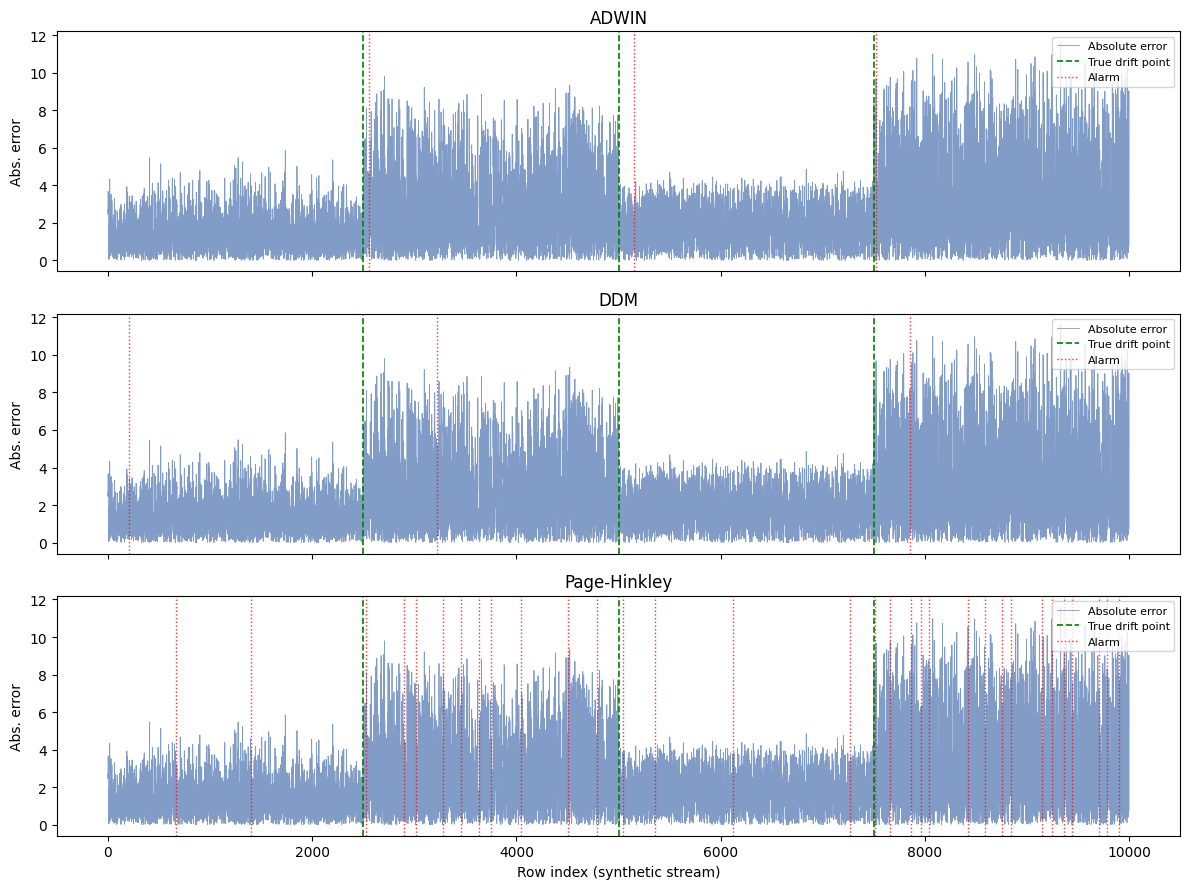

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase4_synthetic_drift_detection.png


In [8]:
fig, axes = plt.subplots(len(dd.DETECTOR_REGISTRY), 1, figsize=(12, 9), sharex=True)

for ax, name in zip(axes, dd.DETECTOR_REGISTRY):
    ax.plot(synthetic_error_stream, color='#4C72B0', linewidth=0.6, alpha=0.7, label='Absolute error')
    for tdp in injection.true_drift_indices:
        ax.axvline(tdp, color='green', linestyle='--', linewidth=1.2,
                    label='True drift point' if tdp == injection.true_drift_indices[0] else None)
    for alarm in synthetic_alarms[name]:
        ax.axvline(alarm, color='red', linestyle=':', linewidth=1.0, alpha=0.8,
                    label='Alarm' if alarm == synthetic_alarms[name][0] else None)
    ax.set_ylabel('Abs. error')
    ax.set_title(dd.DETECTOR_DISPLAY_NAMES[name])
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel('Row index (synthetic stream)')
plt.tight_layout()

fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase4_synthetic_drift_detection.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 5. Observed behaviour on the real (unmodified) stream

Each detector is also run on the genuine, unperturbed test stream, to record drift count and runtime on real data (Chapter 3, Table 3.3), separately from the synthetic ground-truth evaluation above.

In [9]:
X_real = test_df[feature_cols]
y_real = test_df[target_col]
real_error_stream = dd.compute_error_stream(best_model, X_real, y_real)

real_baseline = real_error_stream[:len(real_error_stream) // 4]
real_ddm_threshold = real_baseline.mean() + real_baseline.std()
real_binarized_stream = dd.binarize_error_stream(real_error_stream, real_ddm_threshold)

real_stream_rows = []
for name in dd.DETECTOR_REGISTRY:
    stream_to_use = real_binarized_stream if name in dd.BINARY_DETECTORS else real_error_stream
    with mt.timer() as t:
        alarms = dd.run_detector_on_stream(name, stream_to_use)
    real_stream_rows.append({
        'detector': name,
        'display_name': dd.DETECTOR_DISPLAY_NAMES[name],
        'drift_count_real_stream': len(alarms),
        'runtime_s': t['seconds'],
    })

real_stream_df = pd.DataFrame(real_stream_rows)
real_stream_df

,detector,display_name,drift_count_real_stream,runtime_s
0,adwin,ADWIN,0,0.003322
1,ddm,DDM,1,0.016048
2,page_hinkley,Page-Hinkley,8,0.016216


## 6. Combine results and select the best detector

A naive rule -- rank purely by most drifts detected, then lowest delay -- has a flaw
analogous to the one found in Phase 3: it can reward a detector that fires constantly
(low delay because it is *always* about to fire) while ignoring how often it fires when
it shouldn't. A detector with dozens of false positives against only three true events is
not practically usable for triggering retraining (Chapter 3, Section 3.8), however low its
delay is on the events it does catch.

Detectors are therefore selected using a two-tier rule:

1. **Usability filter**: a detector's false positives on the synthetic stream must not
   exceed the number of true drift points (3) -- a simple, explainable precision-style bar.
   A detector that cries wolf more often than it is right is excluded regardless of its
   delay.
2. **Ranking among usable detectors**: most true drifts detected (descending), then lowest
   mean detection delay (ascending), then fewest false positives (ascending).

In [10]:
MAX_ACCEPTABLE_FALSE_POSITIVES = len(injection.true_drift_indices)  # usability bar: FP <= n_true_drifts

synthetic_rows = []
for name in dd.DETECTOR_REGISTRY:
    ev = synthetic_eval[name]
    synthetic_rows.append({
        'detector': name,
        'display_name': dd.DETECTOR_DISPLAY_NAMES[name],
        'n_true_drifts': ev['n_true_drifts'],
        'n_detected': ev['n_detected'],
        'mean_detection_delay': ev['mean_detection_delay'],
        'n_false_positives': ev['n_false_positives'],
        'synthetic_runtime_s': synthetic_runtimes[name],
    })
synthetic_df = pd.DataFrame(synthetic_rows)

comparison_df = synthetic_df.merge(real_stream_df[['detector', 'drift_count_real_stream', 'runtime_s']], on='detector')
comparison_df = comparison_df.rename(columns={'runtime_s': 'real_stream_runtime_s'})
comparison_df['usable'] = comparison_df['n_false_positives'] <= MAX_ACCEPTABLE_FALSE_POSITIVES

usable_df = comparison_df[comparison_df['usable']]
if usable_df.empty:
    print('WARNING: no detector satisfies the usability filter (FP <=', MAX_ACCEPTABLE_FALSE_POSITIVES, ') --')
    print('falling back to ranking all detectors, flagging that none are cleanly usable as configured.')
    usable_df = comparison_df

ranked = usable_df.sort_values(
    by=['n_detected', 'mean_detection_delay', 'n_false_positives'],
    ascending=[False, True, True],
).reset_index(drop=True)

best_detector_name = ranked.iloc[0]['detector']

print('Usability filter: false positives <=', MAX_ACCEPTABLE_FALSE_POSITIVES)
print()
print(comparison_df[['display_name', 'n_detected', 'mean_detection_delay', 'n_false_positives', 'usable',
                      'drift_count_real_stream', 'real_stream_runtime_s']].to_string(index=False))
print()
print('Selected detector:', dd.DETECTOR_DISPLAY_NAMES[best_detector_name])

Usability filter: false positives <= 3

display_name  n_detected  mean_detection_delay  n_false_positives  usable  drift_count_real_stream  real_stream_runtime_s
       ADWIN           3             76.333333                  0    True                        0               0.003322
         DDM           1            355.000000                  2    True                        1               0.016048
Page-Hinkley           3             31.333333                 29   False                        8               0.016216

Selected detector: ADWIN


## 7. Persist artefacts for later phases

In [11]:
synthetic_path = os.path.join(PROJECT_ROOT, 'results/tables/phase4_synthetic_evaluation.csv')
synthetic_df.to_csv(synthetic_path, index=False)

real_path = os.path.join(PROJECT_ROOT, 'results/tables/phase4_real_stream_evaluation.csv')
real_stream_df.to_csv(real_path, index=False)

artifacts = {
    'best_detector': best_detector_name,
    'best_detector_synthetic_alarms': [int(a) for a in synthetic_alarms[best_detector_name]],
    'best_detector_real_stream_alarm_count': int(real_stream_df.loc[real_stream_df['detector'] == best_detector_name, 'drift_count_real_stream'].iloc[0]),
    'ranking': ranked['detector'].tolist(),
    'selection_rule': 'most injected drifts detected, then lowest mean detection delay, then fewest false positives',
    'injection_points': injection.true_drift_indices,
    'scale_factors': SCALE_FACTORS,
    'tolerance_samples': TOLERANCE,
    'ddm_binarization_threshold_synthetic': float(ddm_threshold),
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved synthetic evaluation to', synthetic_path)
print('Saved real-stream evaluation to', real_path)
print('Saved artefacts to', artifacts_path)
print()
print(artifacts)

Saved synthetic evaluation to /content/drive/MyDrive/dissertation-project/results/tables/phase4_synthetic_evaluation.csv
Saved real-stream evaluation to /content/drive/MyDrive/dissertation-project/results/tables/phase4_real_stream_evaluation.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase4_artifacts.json

{'best_detector': 'adwin', 'best_detector_synthetic_alarms': [2559, 5151, 7519], 'best_detector_real_stream_alarm_count': 0, 'ranking': ['adwin', 'ddm'], 'selection_rule': 'most injected drifts detected, then lowest mean detection delay, then fewest false positives', 'injection_points': [2500, 5000, 7500], 'scale_factors': [1.0, 1.35, 0.75, 1.5], 'tolerance_samples': 500, 'ddm_binarization_threshold_synthetic': 2.4578815384121784}


## Summary

This notebook implements Chapter 3, Section 3.5 and Chapter 4, Section 4.6. All three detectors monitor the same model's per-row error stream, evaluated both against known, synthetically injected drift points (detection delay and false positives, independent of downstream predictive accuracy) and on the genuine test stream (drift count and runtime). The selected detector is carried forward as a fixed artefact into Phase 5 (feature-selection comparison), consistent with the dependency chain in Chapter 3, Table 3.4.